# Wavelet transforms:

### Example 1:

Let's carry out a DWT of this signal:

$f(n) = (2, 4, 6, 8, 9, -2, 3, -4)$ 

Then, carry out an inverse DWT to recover the signal.

In [1]:
import pywt
import matplotlib.pyplot as plt

# https://pywavelets.readthedocs.io/en/latest/

In [2]:
# signal:

f = [2, 4, 6, 8, 9, -2, 3, -4]

print(f, len(f))

[2, 4, 6, 8, 9, -2, 3, -4] 8


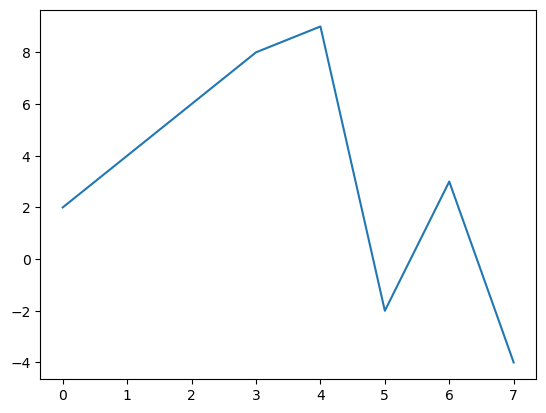

In [3]:
plt.figure()

plt.plot(f)

plt.show()

In [4]:
# DWT:

cA, cD = pywt.dwt(f, 'haar')

In [5]:
print(cA) # approximation coef.
print(cD) # detail coef.

[ 4.24264069  9.89949494  4.94974747 -0.70710678]
[-1.41421356 -1.41421356  7.77817459  4.94974747]


In [6]:
# iDWT

f_recovered = pywt.idwt(cA, cD, 'haar')

In [7]:
print(f)
print(f_recovered)

[2, 4, 6, 8, 9, -2, 3, -4]
[ 2.  4.  6.  8.  9. -2.  3. -4.]


### Wavelet transform analysis:

coeffs = pywt.wavedec(x, 'wavelet', mode ='sym', level = n)

y = pywt.waverec(coeffs, 'wavelet', mode ='sym')

In [8]:
coeffs = pywt.wavedec(f, 'db1', level = 2, mode = 'periodic')

cA2, cD2, cD1 = coeffs

print(cA2)
print(cD2)
print(cD1)

[10.  3.]
[-4.  4.]
[-1.41421356 -1.41421356  7.77817459  4.94974747]


In [9]:
f_recovered2 = pywt.waverec(coeffs, 'db1', mode = 'periodic')

In [10]:
print(f)
print(f_recovered2)

[2, 4, 6, 8, 9, -2, 3, -4]
[ 2.  4.  6.  8.  9. -2.  3. -4.]


### Example 2: Audio file

Download a .wav file.

Decompose the signal in low and high frequencies by using DWT.

Then write the following files:

1. The fully reconstructed signal from the approximation and detail coefficients.


2. The low-frequency signal considering the approximation coefficients only.


3. The high-frequency signal considering the detail coefficients only.


4. Listen to all three audio tracks and compare them to the original one. What do you find?

### Reference file:
https://github.com/wbandabarragan/physics-teaching-data/blob/main/1D-data/ImperialMarch60.wav

In [11]:
from scipy.io import wavfile

import matplotlib.pyplot as plt
import numpy as np

import IPython.display as ipd

### Read wav file:

In [12]:
# Define file path

filepath = "/Users/wbandabarragan/Library/CloudStorage/Dropbox/Teaching_Arxiv/physics-teaching-data/1D-data/"

samplerate, data = wavfile.read(filepath + "ImperialMarch60.wav")

In [18]:
# Check the signal

print(type(samplerate))

print(data.shape)

print(data, np.min(data), np.max(data))

<class 'int'>
(1323000,)
[  -3   -1    0 ...  -97  -95 -127] -31961 31031


In [19]:
ipd.Audio(filepath + "ImperialMarch60.wav")

### Define x and y axes:

In [20]:
# Generate the time axis using the sampling rate
t = np.arange(len(data))/float(samplerate)

# Normalising the signal
data = data/np.max(data)

### Plot signal:

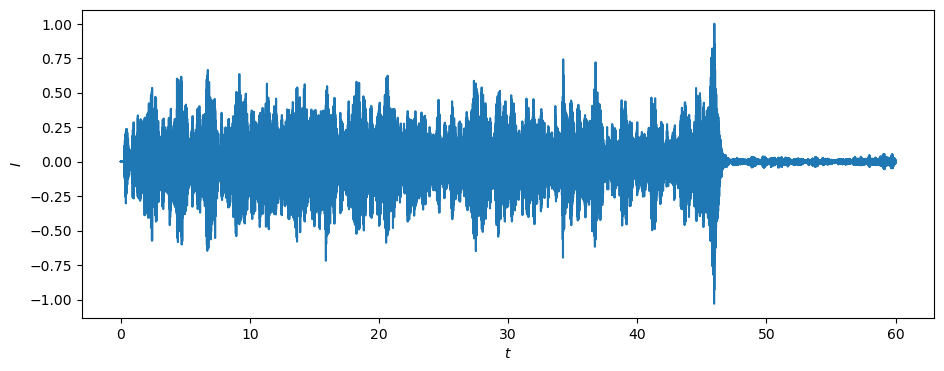

In [22]:
# Plotting the audio track

plt.figure(figsize=(11,4))

plt.plot(t, data)

plt.xlabel(r"$t$")
plt.ylabel(r"$I$")
#plt.xlim(0,2)
plt.show()

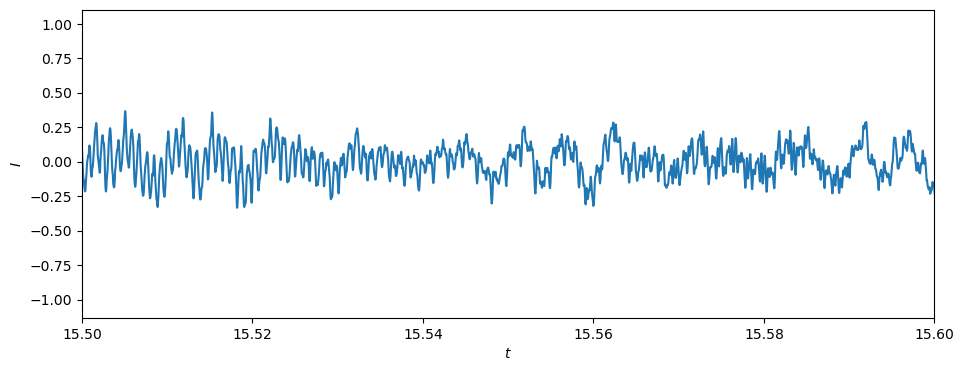

In [24]:
# Plotting the audio track

plt.figure(figsize=(11,4))

plt.plot(t, data)
plt.xlim(15.5,15.6)

plt.xlabel(r"$t$")
plt.ylabel(r"$I$")
plt.show()

### DWT to get coefficients:

In [26]:
cA, cD = pywt.dwt(data, 'bior6.8', 'per')

print(cA.shape, cD.shape, data.shape)

(661500,) (661500,) (1323000,)


In [29]:
# Applying the iDWT
data_reconstruted = pywt.idwt(cA, cD, 'bior6.8', 'per')

# Saving the reconstructed file
wavfile.write(filepath + 'full_reconstructed.wav', samplerate, data_reconstruted)


In [ ]:
#wavfile.write('../sample-data/reconstructed.wav', samplerate, data_reconstruted)



### Comparing the original and the reconstructured signals:

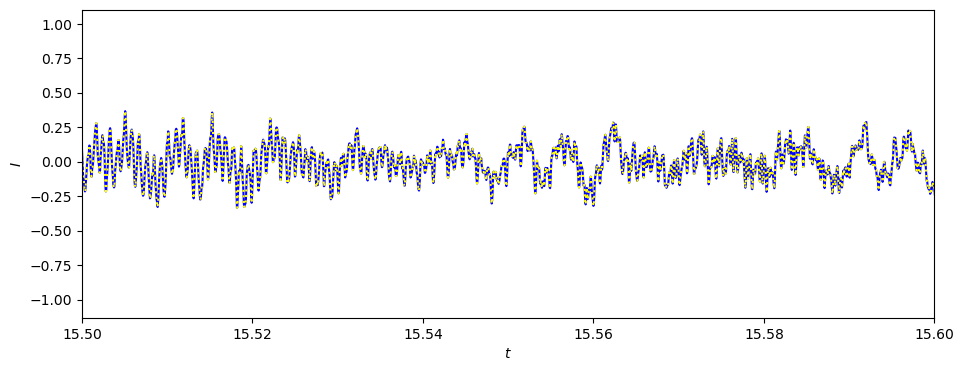

In [31]:
plt.figure(figsize=(11,4))

plt.plot(t, data, "blue")
plt.plot(t, data_reconstruted, linestyle = ":", c="yellow")
plt.xlim(15.5,15.6)

plt.xlabel(r"$t$")
plt.ylabel(r"$I$")
plt.show()

In [33]:
samplerate, data = wavfile.read(filepath + "full_reconstructed.wav")

print(samplerate)

print(data.shape)

22050
(1323000,)


In [34]:
ipd.Audio(filepath + "ImperialMarch60.wav")

#### Isolate the low frequencies (Approximation coefficients)



In [44]:
# Saving the low freq. directly
wavfile.write(filepath + 'only_ca.wav', samplerate, cA) 

# 2nd try:
data_low = pywt.idwt(cA, None, "bior6.8", "per")

# Formatting: https://docs.scipy.org/doc/scipy/reference/generated/scipy.io.wavfile.read.html

data_low_f = np.clip(data_low, -1., +1.).astype(np.float32)
 
wavfile.write(filepath + 'only_ca2.wav', samplerate, data_low)
wavfile.write(filepath + 'only_ca3.wav', samplerate, data_low_f)

#### Isolate the high frequencies (Approximation coefficients)

In [45]:
# Saving the low freq. directly
wavfile.write(filepath + 'only_cd.wav', samplerate, cD) 


# 2nd try:
data_high = pywt.idwt(None, cD, "bior6.8", "per")

# Formatting: https://docs.scipy.org/doc/scipy/reference/generated/scipy.io.wavfile.read.html

data_high_f = np.clip(data_high, -1., +1.).astype(np.float32)

wavfile.write(filepath + 'only_cd2.wav', samplerate, data_high)
wavfile.write(filepath + 'only_cd3.wav', samplerate, data_high_f)

In [46]:
ipd.Audio(filepath + "only_cd3.wav")

#wavfile.write('../sample-data/with_only_cds.wav', samplerate, cD) #high freq.

### Alternative decomposition:

In [49]:
coeffs_audio = pywt.wavedec(data, 'bior6.8', level = 4, mode = 'periodic')

print(len(coeffs_audio))

ca, cd4, cd3, cd2, cd1 = coeffs_audio

5


In [51]:
print(ca.shape)
print(cd1.shape)
print(cd2.shape)
print(cd3.shape)
print(cd4.shape)

(82703,)
(661508,)
(330762,)
(165389,)
(82703,)


In [53]:
# Let's get the original signal again:

recovered_audio = pywt.waverec(coeffs_audio, 'bior6.8', mode = 'periodic')

In [54]:
wavfile.write(filepath + 'full_reconstructed2.wav', samplerate, recovered_audio)

### Only using cD1:

In [60]:
recovered_audio_c2 = pywt.waverec((ca, cd4), 'bior6.8', mode = 'periodic')

In [56]:
wavfile.write(filepath + 'reconstructed_cacd1.wav', samplerate, recovered_audio_c2)

In [57]:
recovered_audio_c5 = pywt.waverec((cd2, cd1[:330762]), 'bior6.8', mode = 'periodic')

In [58]:
wavfile.write(filepath + 'reconstructed_cd1cd2.wav', samplerate, recovered_audio_c5)